# Hydro displacement of natural gas in Tanzania's power sector
**Interrupted time series around the commissioning of the Julius Nyerere Hydropower Project (JNHPP)**

Author: Abbot Josephat Antony

**Question.** Did gas burned for electricity fall when JNHPP came online, by how much, and are the gas and electricity statistics physically consistent with that story?

**Data.** Bank of Tanzania *Consolidated Zonal Economic Reports* (scraped): quarterly gas production, gas consumption by sector, and electricity generation by source. JNHPP turbine timeline compiled from the Daily News corpus.

**Methods.**
1. Edition-aware cleaning of the BoT quarterly tables
2. Interrupted time series (segmented regression, Newey–West SEs)
3. Dose-response on the number of JNHPP turbines operating
4. Physical consistency checks (implied heat rate; gas displaced per GWh of hydro)
5. Unknown-break scan (sup-F) on the long production series

## 1. Setup

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# Paths are relative to the repository root (where this notebook sits)
DATA_DIR    = Path("data/raw")       # bot_gas.csv, bot_electricity.csv (tracked in git)
PRIVATE_DIR = Path("data/private")   # copyrighted news text, NOT tracked in git
OUT         = Path("outputs")        # all tables and figures are saved here
OUT.mkdir(parents=True, exist_ok=True)
print("Outputs will be saved to:", OUT)

NW_LAGS   = 2         # Newey-West lags (quarterly data)
BREAK     = "2024Q2"  # first full quarter after JNHPP turbine 9 (22 Feb 2024)
ALT_BREAK = "2024Q1"  # robustness: quarter of first grid injection

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Outputs will be saved to: outputs


## 2. Load the scraped BoT tables

In [3]:
gas = pd.read_csv(DATA_DIR / "bot_gas.csv", low_memory=False)
ele = pd.read_csv(DATA_DIR / "bot_electricity.csv", low_memory=False)

print("bot_gas:", gas.shape, "| variables:", gas.variable.unique().tolist())
print("bot_electricity:", ele.shape, "| variables:", ele.variable.unique().tolist())
gas.loc[gas.month.notna(), ["year", "month", "variable", "category", "value_mmscf", "doc_title", "latest_edition"]].head()

bot_gas: (559, 24) | variables: ['gas_production', 'gas_consumption']
bot_electricity: (1257, 29) | variables: ['electricity_generation_by_zone', 'electricity_generation_by_plant', 'electricity_generation_by_source']


,year,month,variable,category,value_mmscf,doc_title,latest_edition
1,2015,9.00,gas_production,Mnazi Bay,216.60,Consolidated Zonal Economic Report - Sep-16,1
2,2015,9.00,gas_production,Songo Songo,"8,136.40",Consolidated Zonal Economic Report - Sep-16,1
3,2015,9.00,gas_production,TOTAL,"8,353.00",Consolidated Zonal Economic Report - Sep-16,1
4,2015,12.00,gas_production,Mnazi Bay,"4,186.40",Consolidated Zonal Economic Report - Dec-16,1
5,2015,12.00,gas_production,Songo Songo,"8,118.20",Consolidated Zonal Economic Report - Dec-16,1


## 3. Edition-aware selection of quarterly values

The same quarter appears in several report editions, and editions sometimes disagree. Two problems matter here:

* **Carry-forward errors** — an edition reprints the previous quarter's numbers (e.g. Dec-2022 gas consumption in the Dec-2023 report equals Sep-2022 exactly).
* **Revisions** — later editions change earlier figures, sometimes by a lot.

**Rule:** use the latest edition, *unless* its value equals the previously selected quarter and another edition gives a different value; then use that edition. Every intervention and every >5% disagreement between editions is written to a log.

In [4]:
issues = []

def pick_quarterly(df, value_col, label):
    df = df[df.month.notna()].copy()
    df["q"] = pd.PeriodIndex.from_fields(year=df.year.astype(int),
                                         quarter=(df.month.astype(int) - 1) // 3 + 1, freq="Q")
    df["pub_date"] = pd.to_datetime(df.pub_date, errors="coerce")
    rows = []
    for cat, g in df.groupby("category"):
        prev = None
        for q, gq in g.sort_values("q").groupby("q"):
            gq = gq.dropna(subset=[value_col]).sort_values(["latest_edition", "pub_date"], ascending=False)
            if gq.empty:
                continue
            chosen = gq.iloc[0]
            if prev is not None and np.isclose(chosen[value_col], prev):
                alt = gq[~np.isclose(gq[value_col], prev)]
                if len(alt):
                    issues.append(dict(series=label, category=cat, quarter=str(q),
                                       issue="latest edition repeats previous quarter; replaced",
                                       value_latest=chosen[value_col], value_used=alt.iloc[0][value_col],
                                       source_used=alt.iloc[0].doc_title))
                    chosen = alt.iloc[0]
                else:
                    issues.append(dict(series=label, category=cat, quarter=str(q),
                                       issue="equals previous quarter in all editions; kept",
                                       value_latest=chosen[value_col], value_used=chosen[value_col],
                                       source_used=chosen.doc_title))
            vals = gq[value_col].unique()
            if len(vals) > 1 and (vals.max() - vals.min()) / vals.max() > 0.05:
                issues.append(dict(series=label, category=cat, quarter=str(q),
                                   issue=f"editions disagree >5% ({vals.min():,.1f} to {vals.max():,.1f})",
                                   value_latest=gq.iloc[0][value_col], value_used=chosen[value_col],
                                   source_used=chosen.doc_title))
            rows.append(dict(q=q, category=cat, value=chosen[value_col]))
            prev = chosen[value_col]
    return pd.DataFrame(rows).pivot(index="q", columns="category", values="value")

cons = pick_quarterly(gas[gas.variable == "gas_consumption"], "value_mmscf", "gas_consumption")
prod = pick_quarterly(gas[(gas.variable == "gas_production") & (gas.category == "TOTAL")], "value_mmscf", "gas_production")
elec = pick_quarterly(ele[(ele.variable == "electricity_generation_by_source") &
                          (ele.x_period_type == "quarter_ending")], "value_mwh", "electricity")
print("Quarters available -> consumption:", len(cons), "| production:", len(prod), "| electricity:", len(elec))

Quarters available -> consumption: 18 | production: 42 | electricity: 21


## 4. Build the quarterly panel

In [5]:
panel = pd.DataFrame(index=pd.period_range("2015Q3", "2026Q1", freq="Q"))
panel.index.name = "period"
panel["gas_production"] = prod["TOTAL"]
panel["gas_power"]      = cons["Power generating plants"]
panel["gas_industry"]   = cons["Industries"]
panel["gas_vehicles"]   = cons["Vehicles"]
panel["gas_total"]      = cons["TOTAL"]

mwh_to_gwh = 1 / 1000
panel["hydro_tanesco_gwh"]   = elec["TANESCO plants: hydro"] * mwh_to_gwh
panel["thermal_tanesco_gwh"] = elec["TANESCO plants: thermal"] * mwh_to_gwh
panel["thermal_private_gwh"] = elec["Private plants: thermal"] * mwh_to_gwh
panel["hydro_private_gwh"]   = elec["Private plants: hydro"] * mwh_to_gwh
panel["imports_gwh"]         = elec["Imported"] * mwh_to_gwh
panel["total_gen_gwh"]       = elec["Total (as printed)"] * mwh_to_gwh
panel["thermal_gwh"]         = panel.thermal_tanesco_gwh + panel.thermal_private_gwh

# 2025Q2 electricity is implausible: total 4.2 TWh (vs ~3.3 either side) and thermal doubles
# while gas-for-power falls. Flag it and exclude from the electricity models.
panel["elec_suspect"] = 0
panel.loc[pd.Period("2025Q2", "Q"), "elec_suspect"] = 1
issues.append(dict(series="electricity", category="all", quarter="2025Q2",
                   issue="implausible spike (total 4.2 TWh, thermal 2.1 TWh); excluded from electricity models",
                   value_latest=np.nan, value_used=np.nan, source_used="Consolidated Zonal Economic Report - Sep-25"))

panel["t"] = np.arange(len(panel)) + 1
panel["quarter"] = panel.index.quarter
panel[["gas_production", "gas_power", "gas_industry", "gas_vehicles", "hydro_tanesco_gwh", "thermal_gwh", "total_gen_gwh"]].tail(10)

,gas_production,gas_power,gas_industry,gas_vehicles,hydro_tanesco_gwh,thermal_gwh,total_gen_gwh
period,,,,,,,
2023Q4,"21,935.60","18,315.80","2,983.80",43.20,646.29,"1,936.01","2,642.35"
2024Q1,"20,517.40","17,084.70","2,790.50",46.10,900.97,"1,814.95","2,767.97"
2024Q2,"17,681.30","14,411.40","2,959.10",52.10,"1,379.78","1,515.70","2,968.58"
2024Q3,"15,326.20","11,465.40","3,162.90",61.40,"1,808.14","1,213.24","3,030.36"
2024Q4,"16,013.60","11,806.60","3,606.50",133.00,"2,014.69","1,252.34","3,278.06"
2025Q1,"15,493.50","11,001.60","3,981.40",158.50,"2,140.76","1,084.56","3,252.77"
2025Q2,"14,662.30","10,697.30","3,531.30",200.10,"2,058.62","2,138.54","4,211.21"
2025Q3,"15,838.50","10,691.60","4,348.90",231.80,"2,219.41","1,150.88","3,386.23"
2025Q4,"15,877.00","11,113.40","4,209.00",176.80,"2,349.56","1,168.85","3,533.28"



## 5. JNHPP turbine timeline (treatment intensity)

Turbines operating at the end of each quarter (235 MW each). Dates checked against official statements and contractor releases (October 2026):

| Date | Event | Source |
|---|---|---|
| Feb 2024 | First turbine (unit 9) supplies the grid; announced by the Energy Minister on 25 Feb 2024 | Reuters (26 Feb 2024); TANESCO DG at inauguration (22 Aug 2026) |
| Mar–Apr 2024 | Second unit (unit 8) commissioned; JNHPP at 470 MW | Ministry of Energy statement (Daily News, Jul 2024); TANESCO (The Citizen, 6 Apr 2024) |
| 17 Jul 2024 | Third turbine switched on | Daily News corpus |
| 16 Oct 2024 | Four units (6, 7, 8, 9) commissioned and on the grid | Arab Contractors release |
| Dec 2024 | Five turbines operational | Daily News corpus |
| 31 Jan – 11 Feb 2025 | Eight units installed; ninth being completed | Minister in Parliament (The Citizen); Arab Contractors release |
| 5 Apr 2025 | All nine turbines operational (2,115 MW) | Minister of Energy (The Citizen, 6 Apr 2025) |
| 22 Aug 2026 | Official inauguration | Ahram Online; The Citizen |

**Uncertain quarter:** the end-2024Q3 count could be 3 or 4 (the fourth unit was on the grid by 16 October). Section 17 tests this alternative timeline.


In [6]:
turbines = {"2024Q1": 1, "2024Q2": 2, "2024Q3": 3, "2024Q4": 5, "2025Q1": 8}
panel["jnhpp_turbines"] = 0
for q, n in turbines.items():
    panel.loc[pd.Period(q, "Q"), "jnhpp_turbines"] = n
panel.loc[panel.index >= pd.Period("2025Q2", "Q"), "jnhpp_turbines"] = 9
panel["jnhpp_mw"] = panel.jnhpp_turbines * 235
panel.loc["2023Q4":, ["jnhpp_turbines", "jnhpp_mw"]]

,jnhpp_turbines,jnhpp_mw
period,,
2023Q4,0,0
2024Q1,1,235
2024Q2,2,470
2024Q3,3,705
2024Q4,5,1175
2025Q1,8,1880
2025Q2,9,2115
2025Q3,9,2115
2025Q4,9,2115


In [7]:
# Check the timeline against the news corpus
# Optional: runs only if you have the news corpus locally in data/private/
news_path = PRIVATE_DIR / "news_dailynews.csv"
if news_path.exists():
    news = pd.read_csv(news_path)
    hits = news[news.x_text.str.contains("turbine", case=False, na=False)
                & news.x_text.str.contains("Nyerere|JNHPP", case=False, na=False)]
    hits = hits[(hits.pub_date >= "2024-01") & (hits.pub_date <= "2025-06")]
    print(len(hits), "articles mention JNHPP turbines, Jan 2024 - Jun 2025")
    display(hits[["pub_date", "doc_title"]].sort_values("pub_date").head(20))
else:
    print("News corpus not found in data/private/ - skipping the timeline check.")

News corpus not found in data/private/ - skipping the timeline check.


## 6. Data-issue log

In [8]:
issues_df = pd.DataFrame(issues)
issues_df.to_csv(OUT / "data_issues_log.csv", index=False)
print(issues_df.issue.str.split(" \\(").str[0].value_counts())
issues_df[issues_df.category.isin(["Power generating plants", "TOTAL", "TANESCO plants: hydro", "TANESCO plants: thermal", "all"])]

issue
editions disagree >5%                                29
latest edition repeats previous quarter; replaced     5
equals previous quarter in all editions; kept         5
implausible spike                                     1
Name: count, dtype: int64


,series,category,quarter,issue,value_latest,value_used,source_used
12,gas_consumption,Power generating plants,2022Q4,latest edition repeats previous quarter; replaced,"16,150.80","18,243.40",Consolidated Zonal Economic Report - Mar-23
13,gas_consumption,Power generating plants,2022Q4,"editions disagree >5% (16,150.8 to 18,243.4)","16,150.80","18,243.40",Consolidated Zonal Economic Report - Mar-23
14,gas_consumption,Power generating plants,2023Q3,"editions disagree >5% (16,758.4 to 18,524.8)","18,524.80","18,524.80",Consolidated Zonal Economic Report - Sep 2024
15,gas_consumption,TOTAL,2022Q4,latest edition repeats previous quarter; replaced,"19,184.10","21,212.40",Consolidated Zonal Economic Report - Mar-23
16,gas_consumption,TOTAL,2022Q4,"editions disagree >5% (19,184.1 to 21,212.4)","19,184.10","21,212.40",Consolidated Zonal Economic Report - Mar-23
17,gas_consumption,TOTAL,2023Q3,"editions disagree >5% (20,028.0 to 21,634.9)","21,634.90","21,634.90",Consolidated Zonal Economic Report - Sep 2024
18,gas_consumption,TOTAL,2024Q4,"editions disagree >5% (14,694.1 to 15,549.5)","15,549.50","15,549.50",Consolidated Zonal Economic Report - Dec 25
22,gas_production,TOTAL,2016Q3,"editions disagree >5% (11,067.8 to 12,352.9)","11,067.80","11,067.80",Consolidated Zonal Economic Report - Sep-17
23,gas_production,TOTAL,2018Q3,"editions disagree >5% (13,212.6 to 14,311.7)","14,311.70","14,311.70",Consolidated Zonal Economic Report - Sep-19
34,electricity,TANESCO plants: hydro,2021Q4,"editions disagree >5% (672,207.1 to 733,662.2)","672,207.10","672,207.10",Consolidated Zonal Economic Report - Dec-22


## 7. Descriptive look

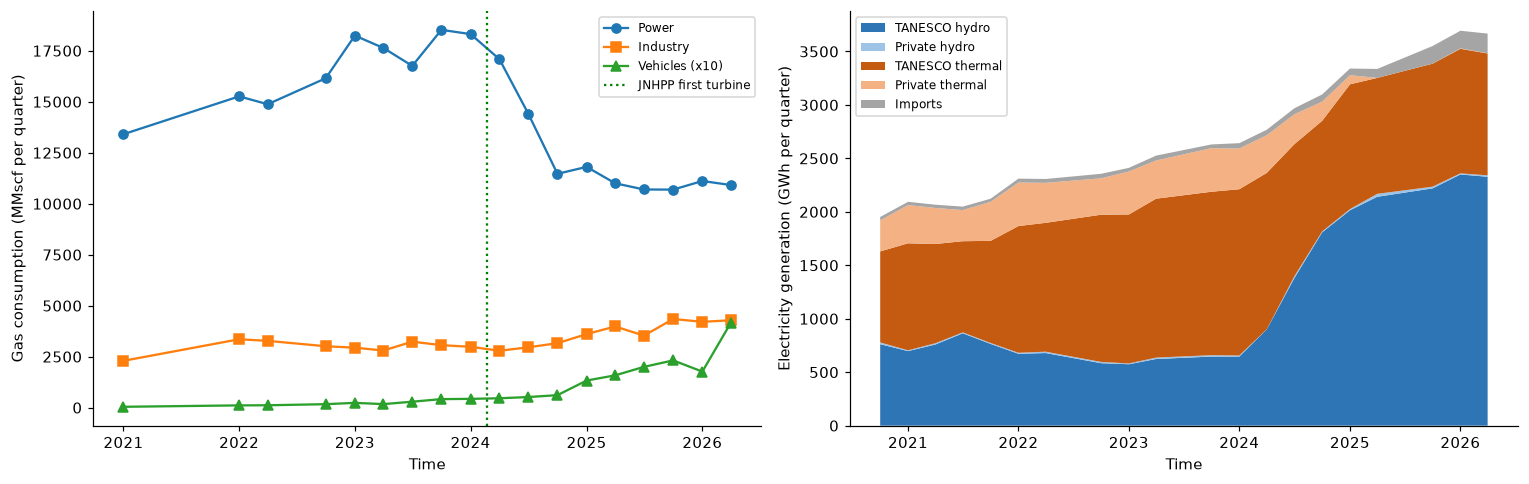

In [9]:
xs = lambda idx: idx.to_timestamp(how="end")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

d = panel.dropna(subset=["gas_total"])
ax[0].plot(xs(d.index), d.gas_power, "o-", label="Power")
ax[0].plot(xs(d.index), d.gas_industry, "s-", label="Industry")
ax[0].plot(xs(d.index), d.gas_vehicles * 10, "^-", label="Vehicles (x10)")
ax[0].axvline(pd.Timestamp("2024-02-22"), color="green", ls=":", label="JNHPP first turbine")
ax[0].set_xlabel("Time"); ax[0].set_ylabel("Gas consumption (MMscf per quarter)")
ax[0].legend(fontsize=8)

e = panel[panel.elec_suspect == 0].dropna(subset=["total_gen_gwh"])
ax[1].stackplot(xs(e.index), e.hydro_tanesco_gwh, e.hydro_private_gwh.fillna(0), e.thermal_tanesco_gwh,
                e.thermal_private_gwh, e.imports_gwh.fillna(0),
                labels=["TANESCO hydro", "Private hydro", "TANESCO thermal", "Private thermal", "Imports"],
                colors=["#2e75b6", "#9dc3e6", "#c55a11", "#f4b183", "#a5a5a5"])
ax[1].set_xlabel("Time"); ax[1].set_ylabel("Electricity generation (GWh per quarter)")
ax[1].legend(fontsize=8, loc="upper left")
plt.tight_layout(); fig.savefig(OUT / "descriptive_gas_and_electricity.png", dpi=200); plt.show()

## 8. Interrupted time series

$$y_t = \beta_0 + \beta_1 t + \beta_2\,\text{post}_t + \beta_3\,(t - T_0 + 1)\,\text{post}_t + \varepsilon_t$$

* $\beta_2$ = immediate level shift at the break; $\beta_3$ = change in quarterly trend after it.
* Counterfactual = the fitted model with $\text{post}=0$ (pre-break trend extended).
* Newey–West SEs with 2 lags. Variants: logs, quarter fixed effects (seasonality from the rains), and an earlier break (2024Q1).
* Two outcomes: **gas for power** (direct, 18 quarters) and **total gas production** (proxy, 42 quarters).

In [10]:
def its(df, y, brk, log=False, seasonal=False):
    d = df.dropna(subset=[y]).copy()
    T0 = df.loc[pd.Period(brk, "Q"), "t"]
    d["post"] = (d.t >= T0).astype(int)
    d["t_post"] = np.where(d.post == 1, d.t - T0 + 1, 0)
    d["dep"] = np.log(d[y]) if log else d[y]
    f = "dep ~ t + post + t_post" + (" + C(quarter)" if seasonal else "")
    m = smf.ols(f, d).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    d["fitted"] = m.predict(d)
    d["counterfactual"] = m.predict(d.assign(post=0, t_post=0))
    if log:
        d["fitted"], d["counterfactual"] = np.exp(d.fitted), np.exp(d.counterfactual)
    p = d[d.post == 1]
    gap = (p.counterfactual - p[y]).sum()
    return m, d, gap, gap / p.counterfactual.sum()

m_main, d_main, gap, gap_pct = its(panel, "gas_power", BREAK)
print(m_main.summary())
(OUT / "its_main_model_summary.txt").write_text(m_main.summary().as_text())
print(f"\nGas for power displaced since {BREAK}: {gap:,.0f} MMscf ({gap_pct:.1%} below counterfactual)")

                            OLS Regression Results                            
Dep. Variable:                    dep   R-squared:                       0.923
Model:                            OLS   Adj. R-squared:                  0.906
Method:                 Least Squares   F-statistic:                     98.10
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           1.23e-09
Time:                        02:55:34   Log-Likelihood:                -146.06
No. Observations:                  18   AIC:                             300.1
Df Residuals:                      14   BIC:                             303.7
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   5702.7000   1421.976      4.010      0.0

### 8.1 Robustness across specifications

In [11]:
specs = [(y, b, lg, ss) for y in ["gas_power", "gas_production"]
         for (b, lg, ss) in [(BREAK, False, False), (BREAK, True, False), (BREAK, False, True), (ALT_BREAK, False, False)]]
rows, fits = [], {}
for y, b, lg, ss in specs:
    m, d, g, gp = its(panel, y, b, lg, ss)
    fits[(y, b, lg, ss)] = d
    rows.append(dict(outcome=y, brk=b, spec=("log" if lg else "level") + (" + quarter FE" if ss else ""), n=int(m.nobs),
                     level_shift=m.params["post"], p_level=m.pvalues["post"],
                     slope_change=m.params["t_post"], p_slope=m.pvalues["t_post"],
                     displaced_mmscf=g, displaced_pct=gp))
its_table = pd.DataFrame(rows)
its_table.to_csv(OUT / "its_results.csv", index=False)
its_table.style.format({"level_shift": "{:,.3f}", "slope_change": "{:,.3f}", "p_level": "{:.3f}",
                        "p_slope": "{:.3f}", "displaced_mmscf": "{:,.0f}", "displaced_pct": "{:.1%}"})

,outcome,brk,spec,n,level_shift,p_level,slope_change,p_slope,displaced_mmscf,displaced_pct
0,gas_power,2024Q2,level,18,"-5,375.896",0.000,-721.031,0.000,"68,964",42.8%
1,gas_power,2024Q2,log,18,-0.355,0.000,-0.052,0.000,"73,301",44.3%
2,gas_power,2024Q2,level + quarter FE,18,"-5,579.448",0.000,-724.825,0.000,"70,729",43.4%
3,gas_power,2024Q1,level,18,"-3,366.209",0.010,"-1,054.398",0.000,"77,744",41.6%
4,gas_production,2024Q2,level,42,"-4,331.737",0.000,-439.099,0.000,"50,461",28.5%
5,gas_production,2024Q2,log,42,-0.260,0.000,-0.028,0.000,"59,580",32.0%
6,gas_production,2024Q2,level + quarter FE,42,"-3,771.019",0.002,-534.738,0.001,"49,419",28.0%
7,gas_production,2024Q1,level,42,"-2,109.202",0.091,-712.692,0.001,"51,054",25.7%


### 8.2 Actual vs counterfactual

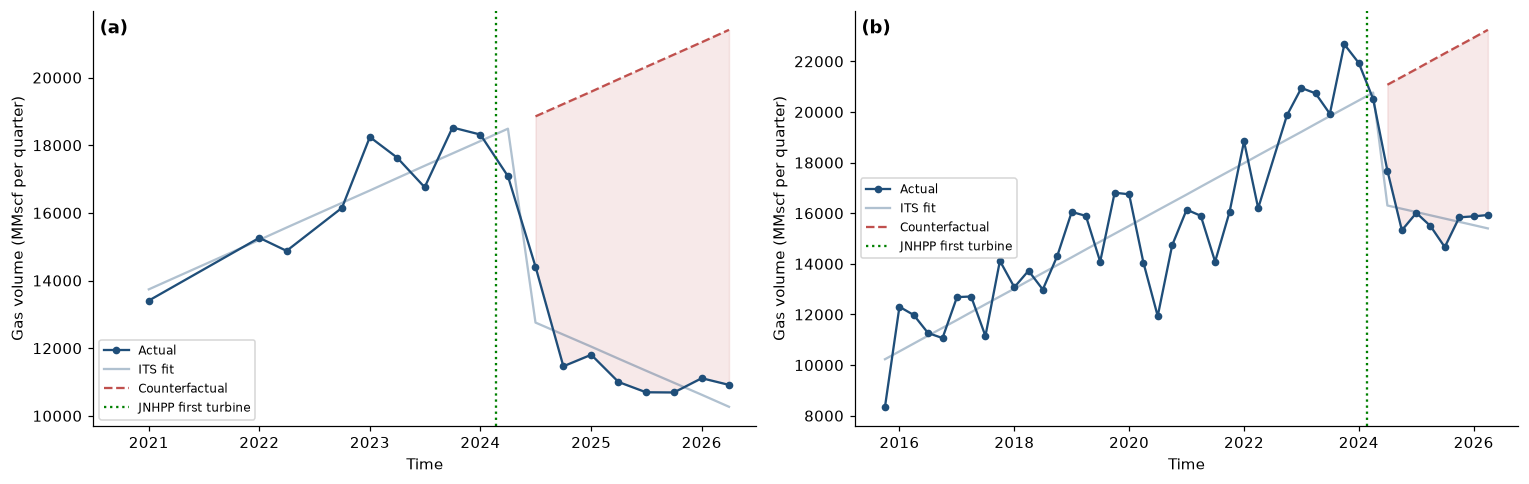

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, y, letter in [(ax[0], "gas_power", "(a)"),
                     (ax[1], "gas_production", "(b)")]:
    d = fits[(y, BREAK, False, False)]
    p = d[d.post == 1]
    a.plot(xs(d.index), d[y], "o-", ms=4, color="#1f4e79", label="Actual")
    a.plot(xs(d.index), d.fitted, color="#1f4e79", alpha=.35, label="ITS fit")
    a.plot(xs(p.index), p.counterfactual, "--", color="#c0504d", label="Counterfactual")
    a.fill_between(xs(p.index), p[y], p.counterfactual, color="#c0504d", alpha=.12)
    a.axvline(pd.Timestamp("2024-02-22"), color="green", ls=":", label="JNHPP first turbine")
    a.text(0.01, 0.98, letter, transform=a.transAxes, fontsize=12, fontweight="bold", va="top")
    a.set_xlabel("Time"); a.set_ylabel("Gas volume (MMscf per quarter)"); a.legend(fontsize=8)
ax[0].set_xlim(pd.Timestamp("2020-07-01"), pd.Timestamp("2026-06-30"))
plt.tight_layout(); fig.savefig(OUT / "its_counterfactual.png", dpi=300); plt.show()

## 9. Dose-response: gas use and the number of JNHPP turbines

Instead of a single on/off break, use the number of turbines operating as a treatment-intensity variable, controlling for the underlying trend.

In [17]:
rows = []
for y in ["gas_power", "gas_production"]:
    for ss in [False, True]:
        d = panel.dropna(subset=[y])
        m = smf.ols(f"{y} ~ jnhpp_turbines + t" + (" + C(quarter)" if ss else ""), d).fit(
            cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
        rows.append(dict(outcome=y, quarter_FE=ss, n=int(m.nobs), per_turbine_mmscf=m.params["jnhpp_turbines"],
                         se=m.bse["jnhpp_turbines"], p=m.pvalues["jnhpp_turbines"]))
dose = pd.DataFrame(rows)
dose.to_csv(OUT / "dose_response_results.csv", index=False)
dose

,outcome,quarter_FE,n,per_turbine_mmscf,se,p
0,gas_power,False,18,-988.86,167.41,0.00
1,gas_power,True,18,"-1,016.51",164.39,0.00
2,gas_production,False,42,-798.64,113.82,0.00
3,gas_production,True,42,-797.86,114.72,0.00


In [18]:
# Benchmark: what would one fully loaded turbine displace?
heat_rate_guess = 9.5                       # MMscf per GWh (estimated in section 10)
for cf in [0.3, 0.5, 0.7]:
    gwh = 235 * cf * 2190 / 1000            # 2,190 hours per quarter
    print(f"capacity factor {cf:.0%}: {gwh:,.0f} GWh/quarter -> {gwh*heat_rate_guess:,.0f} MMscf/quarter")

capacity factor 30%: 154 GWh/quarter -> 1,467 MMscf/quarter
capacity factor 50%: 257 GWh/quarter -> 2,445 MMscf/quarter
capacity factor 70%: 360 GWh/quarter -> 3,422 MMscf/quarter


## 10. Physical consistency checks

If the gas and electricity tables are right, (a) gas for power should track thermal generation at a realistic **heat rate**, and (b) each GWh of hydro (holding total generation fixed) should displace roughly that much gas.

Benchmark: modern combined-cycle plants need about 6.5–7 MMscf per GWh; open-cycle and older plants roughly 9–11 MMscf per GWh (at ~1,037 Btu/scf).

In [19]:
d = panel[panel.elec_suspect == 0].dropna(subset=["gas_power", "thermal_gwh", "hydro_tanesco_gwh"])
m_hr  = smf.ols("gas_power ~ thermal_gwh", d).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
m_own = smf.ols("gas_power ~ thermal_tanesco_gwh + thermal_private_gwh", d).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
m_ds  = smf.ols("gas_power ~ hydro_tanesco_gwh + total_gen_gwh", d).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})

print(f"n = {int(m_hr.nobs)} quarters")
print(f"Implied heat rate:            {m_hr.params['thermal_gwh']:.2f} MMscf/GWh  (p = {m_hr.pvalues['thermal_gwh']:.4f}, R2 = {m_hr.rsquared:.2f})")
print(f"Gas displaced per GWh hydro:  {m_ds.params['hydro_tanesco_gwh']:.2f} MMscf/GWh  (p = {m_ds.pvalues['hydro_tanesco_gwh']:.4f})")
print("\nBy plant owner:"); print(m_own.summary().tables[1])

(OUT / "physical_consistency_models.txt").write_text(
    "HEAT RATE\n" + m_hr.summary().as_text() + "\n\nBY OWNER\n" + m_own.summary().as_text()
    + "\n\nDISPLACEMENT\n" + m_ds.summary().as_text())

n = 16 quarters
Implied heat rate:            9.54 MMscf/GWh  (p = 0.0000, R2 = 0.98)
Gas displaced per GWh hydro:  -8.79 MMscf/GWh  (p = 0.0000)

By plant owner:
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept             569.2135    372.940      1.526      0.127    -161.735    1300.162
thermal_tanesco_gwh     9.0300      0.305     29.654      0.000       8.433       9.627
thermal_private_gwh    10.0899      0.407     24.790      0.000       9.292      10.888


6307

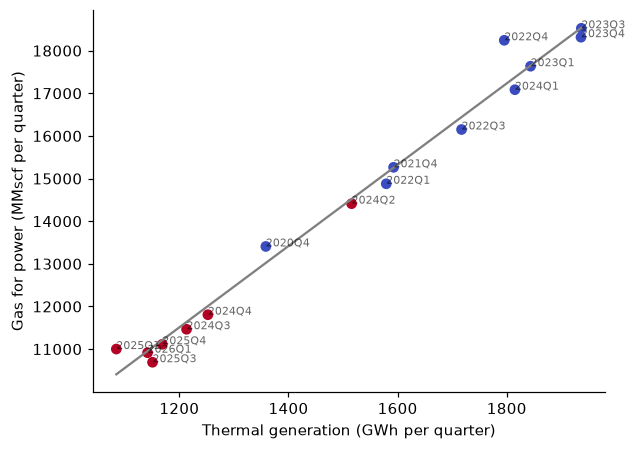

In [20]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(d.thermal_gwh, d.gas_power, c=(d.index >= pd.Period(BREAK, "Q")), cmap="coolwarm")
xx = np.linspace(d.thermal_gwh.min(), d.thermal_gwh.max(), 50)
ax.plot(xx, m_hr.params["Intercept"] + m_hr.params["thermal_gwh"] * xx, color="grey")
for q, r in d.iterrows():
    ax.annotate(str(q), (r.thermal_gwh, r.gas_power), fontsize=7, alpha=.6)
ax.set_xlabel("Thermal generation (GWh per quarter)"); ax.set_ylabel("Gas for power (MMscf per quarter)")
fig.savefig(OUT / "heat_rate_scatter.png", dpi=200, bbox_inches="tight"); plt.show()


## 11. Where does the data put the break? (original sup-F scan)

**Caution:** with 15% trimming, 2024Q2 is the *last* candidate the scan can test, and the F-statistic is already above the critical value from 2022 because of the strong growth trend. This scan is therefore not decisive on its own; Section 14 gives the corrected version.


sup-F = 31.2 at 2024Q2


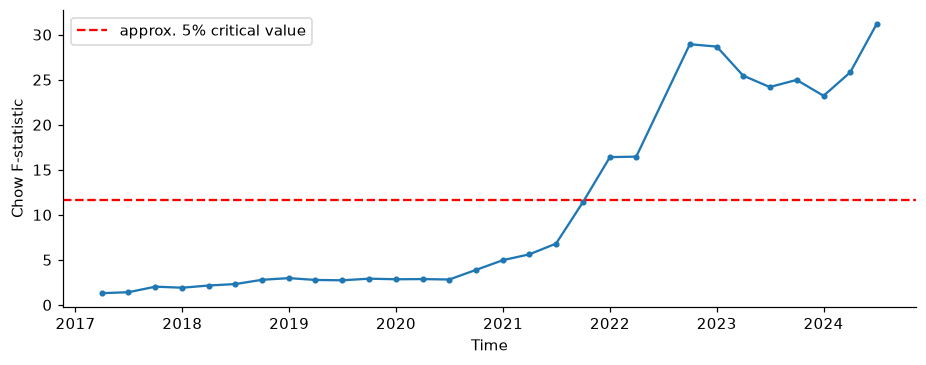

In [21]:
d = panel.dropna(subset=["gas_production"]).copy()
n = len(d)
base = smf.ols("gas_production ~ t", d).fit()
scan = []
for i in range(int(0.15 * n), int(0.85 * n)):
    T0 = d.t.iloc[i]
    dd = d.assign(post=(d.t >= T0).astype(int))
    dd["t_post"] = np.where(dd.post == 1, dd.t - T0 + 1, 0)
    m = smf.ols("gas_production ~ t + post + t_post", dd).fit()
    scan.append(dict(break_quarter=d.index[i], F=((base.ssr - m.ssr) / 2) / (m.ssr / m.df_resid)))
scan = pd.DataFrame(scan)
best = scan.loc[scan.F.idxmax()]
print(f"sup-F = {best.F:.1f} at {best.break_quarter}")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(xs(pd.PeriodIndex(scan.break_quarter)), scan.F, "o-", ms=3)
ax.axhline(11.7, color="red", ls="--", label="approx. 5% critical value")
ax.set_xlabel("Time"); ax.set_ylabel("Chow F-statistic"); ax.legend()
fig.savefig(OUT / "break_scan_plot.png", dpi=200, bbox_inches="tight"); plt.show()
scan.to_csv(OUT / "break_scan_gas_production.csv", index=False)

## 12. Small-sample inference

The direct gas-for-power series has 18 quarters, where Newey–West standard errors can be unreliable. Four checks:

1. Classical OLS, HC3 (robust for small samples) and Newey–West with a small-sample correction
2. **Wild bootstrap** (Rademacher weights, restricted residuals) for the joint null that the break has no effect (level shift = slope change = 0), and for the level shift alone

In [22]:
def its_design(df, y, brk):
    d = df.dropna(subset=[y]).copy()
    T0 = df.loc[pd.Period(brk, "Q"), "t"]
    d["post"] = (d.t >= T0).astype(int)
    d["t_post"] = np.where(d.post == 1, d.t - T0 + 1, 0)
    return d

se_rows = []
for y in ["gas_power", "gas_production"]:
    d = its_design(panel, y, BREAK)
    f = f"{y} ~ t + post + t_post"
    for label, kw in [("OLS classical", {}),
                      ("HC3", dict(cov_type="HC3")),
                      ("Newey-West", dict(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})),
                      ("Newey-West, small-sample corrected",
                       dict(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS, "use_correction": True}))]:
        m = smf.ols(f, d).fit(**kw)
        se_rows.append(dict(outcome=y, se_type=label, n=int(m.nobs),
                            level_shift=m.params["post"], se_level=m.bse["post"], p_level=m.pvalues["post"],
                            slope_change=m.params["t_post"], se_slope=m.bse["t_post"], p_slope=m.pvalues["t_post"]))
se_table = pd.DataFrame(se_rows)
se_table.to_csv(OUT / "inference_se_comparison.csv", index=False)
se_table

,outcome,se_type,n,level_shift,se_level,p_level,slope_change,se_slope,p_slope
0,gas_power,OLS classical,18,"-5,375.90",863.41,0.00,-721.03,160.69,0.00
1,gas_power,HC3,18,"-5,375.90","1,671.38",0.00,-721.03,281.69,0.01
2,gas_power,Newey-West,18,"-5,375.90",993.01,0.00,-721.03,114.02,0.00
3,gas_power,"Newey-West, small-sample corrected",18,"-5,375.90","1,125.97",0.00,-721.03,129.29,0.00
4,gas_production,OLS classical,42,"-4,331.74","1,274.65",0.00,-439.10,232.74,0.07
5,gas_production,HC3,42,"-4,331.74","1,419.97",0.00,-439.10,225.91,0.05
6,gas_production,Newey-West,42,"-4,331.74",863.61,0.00,-439.10,114.07,0.00
7,gas_production,"Newey-West, small-sample corrected",42,"-4,331.74",907.93,0.00,-439.10,119.93,0.00


In [23]:
rng = np.random.default_rng(20261023)
B = 9999

def wild_bootstrap_p(d, y, restricted_cols, full_cols, test_cols, B=B):
    """Wild bootstrap p-value (Rademacher, restricted residuals) for H0: test_cols = 0."""
    Y = d[y].to_numpy(float)
    Xr = np.column_stack([np.ones(len(d))] + [d[c].to_numpy(float) for c in restricted_cols])
    Xf = np.column_stack([np.ones(len(d))] + [d[c].to_numpy(float) for c in full_cols])
    q, k = len(test_cols), Xf.shape[1]

    def fstat(yv):
        br = np.linalg.lstsq(Xr, yv, rcond=None)[0]; ssr_r = ((yv - Xr @ br) ** 2).sum()
        bf = np.linalg.lstsq(Xf, yv, rcond=None)[0]; ssr_f = ((yv - Xf @ bf) ** 2).sum()
        return ((ssr_r - ssr_f) / q) / (ssr_f / (len(yv) - k))

    F_obs = fstat(Y)
    br = np.linalg.lstsq(Xr, Y, rcond=None)[0]
    fit_r, res_r = Xr @ br, Y - Xr @ br
    V = rng.choice([-1.0, 1.0], size=(B, len(Y)))
    F_boot = np.array([fstat(fit_r + res_r * v) for v in V])
    return F_obs, (1 + (F_boot >= F_obs).sum()) / (B + 1)

boot_rows = []
for y in ["gas_power", "gas_production"]:
    d = its_design(panel, y, BREAK)
    F, p = wild_bootstrap_p(d, y, ["t"], ["t", "post", "t_post"], ["post", "t_post"])
    boot_rows.append(dict(outcome=y, null="no break (level & slope = 0)", F=F, wild_bootstrap_p=p, n=len(d)))
    F, p = wild_bootstrap_p(d, y, ["t", "t_post"], ["t", "post", "t_post"], ["post"])
    boot_rows.append(dict(outcome=y, null="no level shift", F=F, wild_bootstrap_p=p, n=len(d)))
boot = pd.DataFrame(boot_rows)
boot.to_csv(OUT / "wild_bootstrap_tests.csv", index=False)
boot

,outcome,null,F,wild_bootstrap_p,n
0,gas_power,no break (level & slope = 0),51.40,0.00,18
1,gas_power,no level shift,38.77,0.00,18
2,gas_production,no break (level & slope = 0),31.22,0.00,42
3,gas_production,no level shift,11.55,0.01,42


## 13. Placebo tests

**(a) Placebo in time.** Using only pre-JNHPP data (up to 2023Q4), re-estimate the ITS on total gas production at every fake break date that leaves at least four post-break quarters. If the method simply finds "breaks" everywhere, fake dates would produce shifts as large as the real one.

**(b) Placebo outcome.** JNHPP should not reduce gas used by *industry*. An ITS on industrial gas at the same break should show no fall.

23 placebo break dates (2017Q1-2022Q4)
Real level shift: -4,332 MMscf (t = -5.02)
Placebo shifts: min -4,048, median -1,107, max 2,402
Share of placebos with a fall at least as large: p = 0.042;  |t| at least as large: p = 0.125


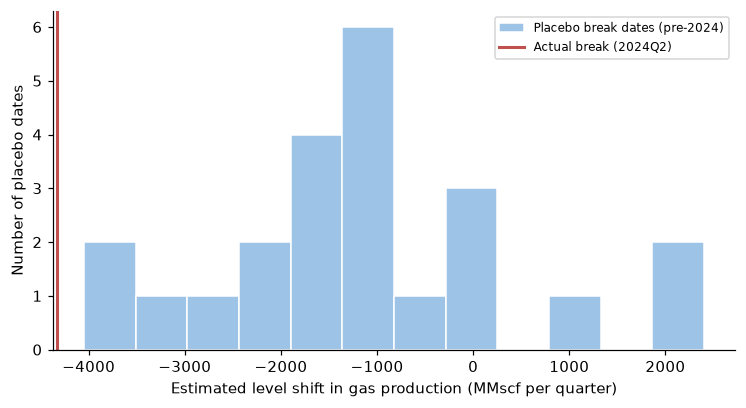

In [24]:
pre = panel[panel.index <= pd.Period("2023Q4", "Q")].dropna(subset=["gas_production"])
cands = [q for q in pre.index if pd.Period("2017Q1", "Q") <= q and (pre.index > q).sum() >= 4]

plac = []
for q in cands:
    d = its_design(pre, "gas_production", str(q))
    m = smf.ols("gas_production ~ t + post + t_post", d).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    plac.append(dict(fake_break=str(q), level_shift=m.params["post"], t_level=m.tvalues["post"]))
plac = pd.DataFrame(plac)

m_real = smf.ols("gas_production ~ t + post + t_post", its_design(panel, "gas_production", BREAK)).fit(
    cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
real_shift, real_t = m_real.params["post"], m_real.tvalues["post"]
p_shift = (1 + (plac.level_shift <= real_shift).sum()) / (len(plac) + 1)
p_t = (1 + (plac.t_level.abs() >= abs(real_t)).sum()) / (len(plac) + 1)
plac.to_csv(OUT / "placebo_in_time.csv", index=False)

print(f"{len(plac)} placebo break dates (2017Q1-{plac.fake_break.iloc[-1]})")
print(f"Real level shift: {real_shift:,.0f} MMscf (t = {real_t:.2f})")
print(f"Placebo shifts: min {plac.level_shift.min():,.0f}, median {plac.level_shift.median():,.0f}, max {plac.level_shift.max():,.0f}")
print(f"Share of placebos with a fall at least as large: p = {p_shift:.3f};  |t| at least as large: p = {p_t:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(plac.level_shift, bins=12, color="#9dc3e6", edgecolor="white", label="Placebo break dates (pre-2024)")
ax.axvline(real_shift, color="#c0504d", lw=2, label=f"Actual break ({BREAK})")
ax.set_xlabel("Estimated level shift in gas production (MMscf per quarter)")
ax.set_ylabel("Number of placebo dates")
ax.legend(fontsize=8)
fig.savefig(OUT / "placebo_in_time.png", dpi=300, bbox_inches="tight"); plt.show()

In [25]:
# (b) Placebo outcome: industrial gas use
m_ind, d_ind, gap_ind, gap_ind_pct = its(panel, "gas_industry", BREAK)
print(m_ind.summary().tables[1])
print(f"\nIndustrial gas, change vs counterfactual after {BREAK}: {-gap_ind:,.0f} MMscf ({-gap_ind_pct:+.1%})")
print("A non-negative level shift supports attributing the fall in power-sector gas to JNHPP, not to a general gas supply problem.")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   2418.4508    810.157      2.985      0.003     830.571    4006.330
t             18.6361     26.040      0.716      0.474     -32.402      69.675
post        -182.8962    130.396     -1.403      0.161    -438.467      72.674
t_post       175.3044     35.337      4.961      0.000     106.045     244.564

Industrial gas, change vs counterfactual after 2024Q2: 4,848 MMscf (+19.2%)
A non-negative level shift supports attributing the fall in power-sector gas to JNHPP, not to a general gas supply problem.


## 14. Corrected break-date scan

Two changes from Section 11: (1) 10% trimming on the production series so quarters after 2024Q2 can be tested, and a **level-only** break model that targets the discontinuity rather than the trend; (2) the same scan on the **gas-for-power** series itself. Shaded areas are outside the search window.

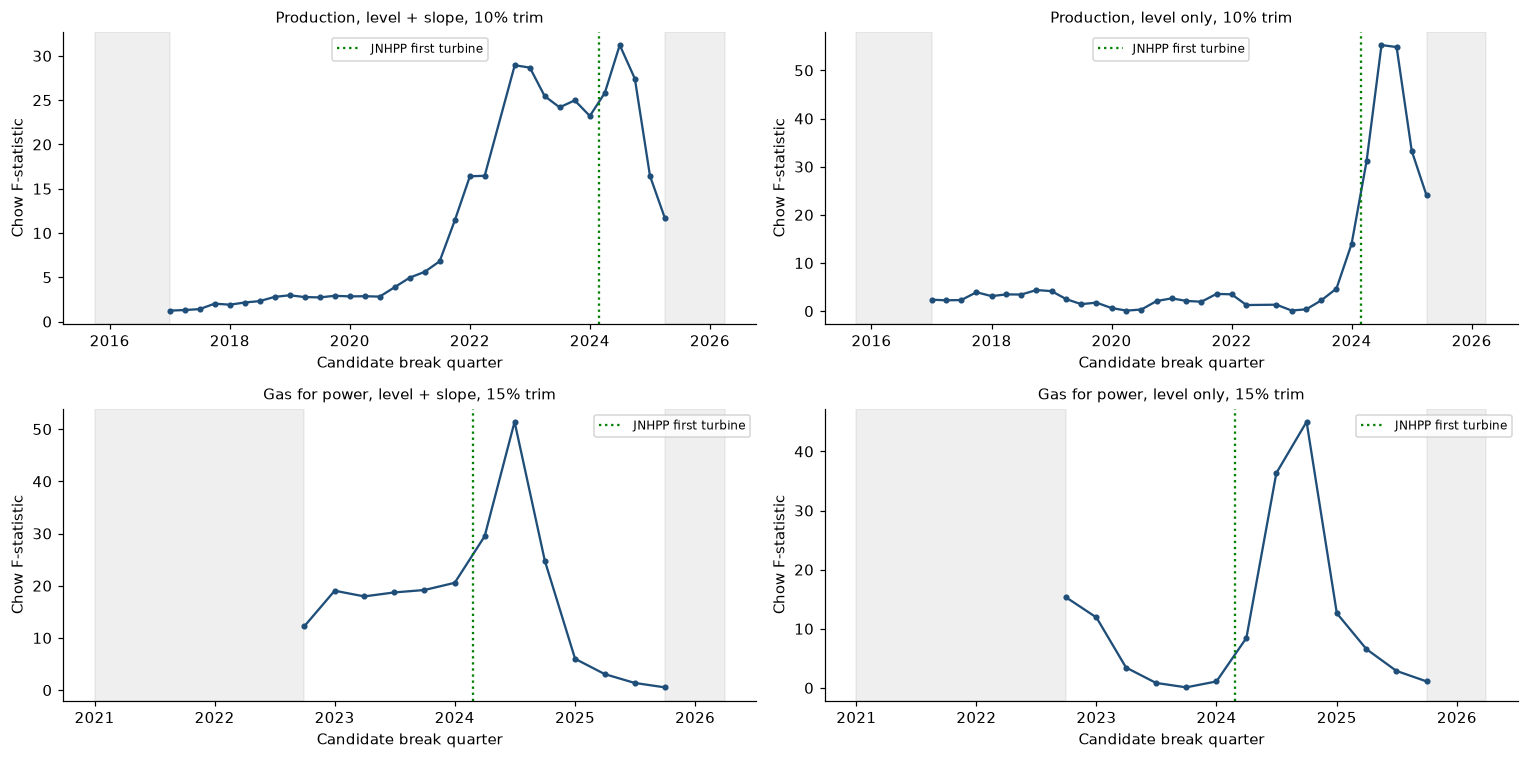

,scan,n,first_candidate,last_candidate,argmax,sup_F,top3
0,"Production, level + slope, 10% trim",42,2016Q4,2025Q1,2024Q2,31.22,"2024Q2, 2022Q3, 2022Q4"
1,"Production, level only, 10% trim",42,2016Q4,2025Q1,2024Q2,55.26,"2024Q2, 2024Q3, 2024Q4"
2,"Gas for power, level + slope, 15% trim",18,2022Q3,2025Q3,2024Q2,51.40,"2024Q2, 2024Q1, 2024Q3"
3,"Gas for power, level only, 15% trim",18,2022Q3,2025Q3,2024Q3,45.01,"2024Q3, 2024Q2, 2022Q3"


In [26]:
def scan(df, y, trim, model="level_slope"):
    d = df.dropna(subset=[y]).copy()
    n = len(d)
    base = smf.ols(f"{y} ~ t", d).fit()
    q_restr = 2 if model == "level_slope" else 1
    out = []
    for i in range(max(2, int(np.ceil(trim * n))), int(np.floor((1 - trim) * n)) + 1):
        if i >= n - 1:
            break
        T0 = d.t.iloc[i]
        dd = d.assign(post=(d.t >= T0).astype(int))
        dd["t_post"] = np.where(dd.post == 1, dd.t - T0 + 1, 0)
        f = f"{y} ~ t + post + t_post" if model == "level_slope" else f"{y} ~ t + post"
        m = smf.ols(f, dd).fit()
        out.append(dict(break_quarter=d.index[i], F=((base.ssr - m.ssr) / q_restr) / (m.ssr / m.df_resid)))
    return pd.DataFrame(out), d

scans = {
    "Production, level + slope, 10% trim": scan(panel, "gas_production", 0.10, "level_slope"),
    "Production, level only, 10% trim":    scan(panel, "gas_production", 0.10, "level"),
    "Gas for power, level + slope, 15% trim": scan(panel, "gas_power", 0.15, "level_slope"),
    "Gas for power, level only, 15% trim":    scan(panel, "gas_power", 0.15, "level"),
}
summary_scan = []
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharey=False)
for ax, (name, (s, d)) in zip(axes.ravel(), scans.items()):
    best = s.loc[s.F.idxmax()]
    top3 = ", ".join(str(q) for q in s.nlargest(3, "F").break_quarter)
    summary_scan.append(dict(scan=name, n=len(d), first_candidate=str(s.break_quarter.iloc[0]),
                             last_candidate=str(s.break_quarter.iloc[-1]), argmax=str(best.break_quarter),
                             sup_F=best.F, top3=top3))
    ax.plot(xs(pd.PeriodIndex(s.break_quarter)), s.F, "o-", ms=3, color="#1f4e79")
    ax.axvspan(xs(d.index)[0], xs(pd.PeriodIndex([s.break_quarter.iloc[0]]))[0], color="grey", alpha=.12)
    ax.axvspan(xs(pd.PeriodIndex([s.break_quarter.iloc[-1]]))[0], xs(d.index)[-1], color="grey", alpha=.12)
    ax.axvline(pd.Timestamp("2024-02-25"), color="green", ls=":", label="JNHPP first turbine")
    ax.set_title(name, fontsize=10); ax.set_xlabel("Candidate break quarter"); ax.set_ylabel("Chow F-statistic")
    ax.legend(fontsize=8)
plt.tight_layout(); fig.savefig(OUT / "break_scan_corrected.png", dpi=300, bbox_inches="tight"); plt.show()
summary_scan = pd.DataFrame(summary_scan)
summary_scan.to_csv(OUT / "break_scan_corrected_summary.csv", index=False)
summary_scan

## 15. Supply-capped counterfactual range

The trend counterfactual (Section 8) assumes gas for power would have kept growing at the 2020–2024 pace. But in 2023 Tanzania had months-long power rationing while gas plants ran near their limit, so gas supply was close to binding. Three counterfactuals for the post-break quarters:

* **Upper bound — trend:** pre-break linear trend extended.
* **Lower bound — supply-capped:** the trend, capped at the highest gas-for-power level ever observed before the break (2023, a rationing year).
* **Engineering need:** gas that would have been needed to replace JNHPP-era hydro growth with gas generation = actual gas + heat rate × (TANESCO hydro − pre-JNHPP hydro baseline). Where this exceeds the cap, the gap is electricity that could not have been supplied by gas.

In [27]:
HR = m_hr.params["thermal_gwh"]          # implied heat rate, MMscf per GWh (Section 10)
CAP = panel.loc[panel.index < pd.Period(BREAK, "Q"), "gas_power"].max()
CAP_Q = panel.loc[panel.index < pd.Period(BREAK, "Q"), "gas_power"].idxmax()
pre_hydro = panel.loc[(panel.index < pd.Period("2024Q1", "Q")) & (panel.elec_suspect == 0), "hydro_tanesco_gwh"].dropna()
HYDRO_BASE = pre_hydro.mean()
HYDRO_BASE_2023 = pre_hydro[pre_hydro.index >= pd.Period("2023Q1", "Q")].mean()
print(f"Heat rate {HR:.2f} MMscf/GWh | supply cap {CAP:,.0f} MMscf/quarter ({CAP_Q}) | "
      f"pre-JNHPP hydro baseline {HYDRO_BASE:,.0f} GWh/quarter (2023 only: {HYDRO_BASE_2023:,.0f})")

cf = d_main[d_main.post == 1][["gas_power", "counterfactual"]].rename(columns={"counterfactual": "cf_trend"})
cf["cf_capped"] = np.minimum(cf.cf_trend, CAP)
cf = cf.join(panel[["hydro_tanesco_gwh", "elec_suspect"]])
cf.loc[cf.elec_suspect == 1, "hydro_tanesco_gwh"] = np.nan          # 2025Q2 electricity is suspect
cf["gas_need"] = cf.gas_power + HR * (cf.hydro_tanesco_gwh - HYDRO_BASE)
cf["unmet_gwh"] = np.maximum(0, cf.gas_need - CAP) / HR
cf["displaced_trend"] = cf.cf_trend - cf.gas_power
cf["displaced_capped"] = cf.cf_capped - cf.gas_power
cf["displaced_need_capped"] = np.minimum(cf.gas_need, CAP) - cf.gas_power
cf.to_csv(OUT / "counterfactual_range_by_quarter.csv")

totals = pd.DataFrame({
    "scenario": ["Upper bound: trend", "Lower bound: supply-capped trend", "Engineering need, capped at supply (excl. 2025Q2)"],
    "displaced_mmscf": [cf.displaced_trend.sum(), cf.displaced_capped.sum(), cf.displaced_need_capped.sum()],
    "quarters": [len(cf), len(cf), cf.gas_need.notna().sum()],
})
totals["pct_of_counterfactual"] = totals.displaced_mmscf / np.array(
    [cf.cf_trend.sum(), cf.cf_capped.sum(), (cf.gas_power + cf.displaced_need_capped).sum()])
totals.to_csv(OUT / "counterfactual_range_totals.csv", index=False)
print(f"\nElectricity gas could NOT have supplied without JNHPP: {cf.unmet_gwh.sum():,.0f} GWh over {cf.unmet_gwh.notna().sum()} quarters")
display(cf.round(1))
totals

Heat rate 9.54 MMscf/GWh | supply cap 18,525 MMscf/quarter (2023Q3) | pre-JNHPP hydro baseline 689 GWh/quarter (2023 only: 639)

Electricity gas could NOT have supplied without JNHPP: 4,355 GWh over 7 quarters


,gas_power,cf_trend,cf_capped,hydro_tanesco_gwh,elec_suspect,gas_need,unmet_gwh,displaced_trend,displaced_capped,displaced_need_capped
period,,,,,,,,,,
2024Q2,"14,411.40","18,854.80","18,524.80","1,379.80",0,"20,997.20",259.20,"4,443.40","4,113.40","4,113.40"
2024Q3,"11,465.40","19,220.10","18,524.80","1,808.10",0,"22,136.90",378.70,"7,754.70","7,059.40","7,059.40"
2024Q4,"11,806.60","19,585.40","18,524.80","2,014.70",0,"24,448.20",621.00,"7,778.80","6,718.20","6,718.20"
2025Q1,"11,001.60","19,950.80","18,524.80","2,140.80",0,"24,845.70",662.70,"8,949.20","7,523.20","7,523.20"
2025Q2,"10,697.30","20,316.10","18,524.80",NaN,1,NaN,NaN,"9,618.80","7,827.50",NaN
2025Q3,"10,691.60","20,681.40","18,524.80","2,219.40",0,"25,285.90",708.80,"9,989.80","7,833.20","7,833.20"
2025Q4,"11,113.40","21,046.80","18,524.80","2,349.60",0,"26,949.10",883.20,"9,933.40","7,411.40","7,411.40"
2026Q1,"10,915.80","21,412.10","18,524.80","2,328.20",0,"26,547.30",841.10,"10,496.30","7,609.00","7,609.00"


,scenario,displaced_mmscf,quarters,pct_of_counterfactual
0,Upper bound: trend,"68,964.29",8,0.43
1,Lower bound: supply-capped trend,"56,095.30",8,0.38
2,"Engineering need, capped at supply (excl. 2025Q2)","48,267.80",7,0.37


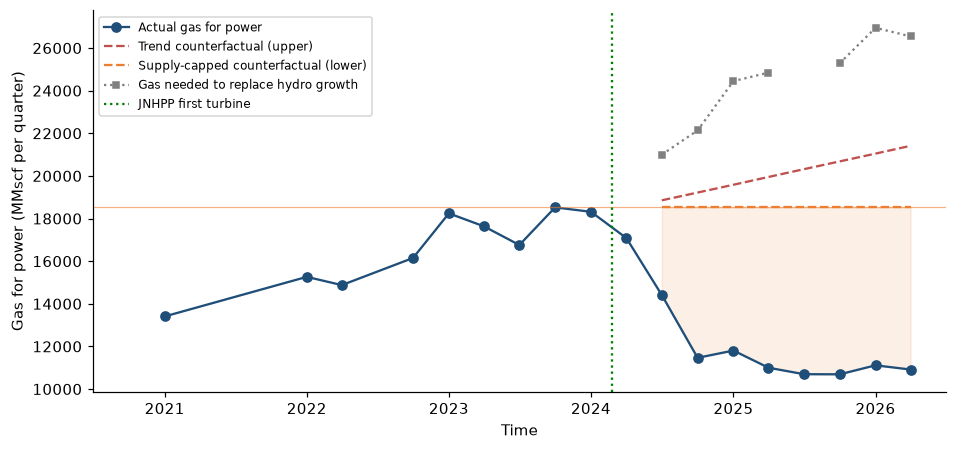

In [28]:
fig, ax = plt.subplots(figsize=(10, 4.5))
dd = d_main
ax.plot(xs(dd.index), dd.gas_power, "o-", color="#1f4e79", label="Actual gas for power")
ax.plot(xs(cf.index), cf.cf_trend, "--", color="#c0504d", label="Trend counterfactual (upper)")
ax.plot(xs(cf.index), cf.cf_capped, "--", color="#ed7d31", label="Supply-capped counterfactual (lower)")
ax.plot(xs(cf.index), cf.gas_need, ":", marker="s", ms=4, color="grey", label="Gas needed to replace hydro growth")
ax.axhline(CAP, color="#ed7d31", lw=.8, alpha=.6)
ax.fill_between(xs(cf.index), cf.gas_power, cf.cf_capped, color="#ed7d31", alpha=.12)
ax.axvline(pd.Timestamp("2024-02-25"), color="green", ls=":", label="JNHPP first turbine")
ax.set_xlim(pd.Timestamp("2020-07-01"), pd.Timestamp("2026-06-30"))
ax.set_xlabel("Time"); ax.set_ylabel("Gas for power (MMscf per quarter)"); ax.legend(fontsize=8, loc="upper left")
fig.savefig(OUT / "counterfactual_range.png", dpi=300, bbox_inches="tight"); plt.show()

## 16. Avoided CO₂ and value of the displaced gas

Assumptions (edit below):

* Heating value **1,037 Btu per scf** (so 1 MMscf ≈ 1,037 MMBtu); sensitivity 1,000–1,050.
* Emission factor **53.06 kg CO₂ per MMBtu** for natural gas combustion (US EPA).
* Gas prices: **US$2.57/MMBtu** = contract wellhead US$1.98 + processing/transport US$0.59 under the PAET supply agreement with TANESCO (Peng & Poudineh, OIES 2016); **US$5.36/MMBtu** = feedgas price at Kinyerezi announced by EWURA (JICA, Domestic Natural Gas study). **Confirm the current EWURA gas price order before publication.**

CO₂ figures are avoided combustion emissions from gas only; they do not net out reservoir emissions from JNHPP.

In [29]:
BTU_PER_SCF = 1037
EF_KG_PER_MMBTU = 53.06
PRICES = {"US$2.57/MMBtu (PAET-TANESCO contract)": 2.57, "US$5.36/MMBtu (EWURA, Kinyerezi)": 5.36}

val = totals[["scenario", "displaced_mmscf"]].copy()
val["mmbtu_million"] = val.displaced_mmscf * BTU_PER_SCF / 1e6
val["co2_mt"] = val.mmbtu_million * 1e6 * EF_KG_PER_MMBTU / 1e9
val["co2_mt_range_1000_1050"] = [f"{x*1000/BTU_PER_SCF:.2f}-{x*1050/BTU_PER_SCF:.2f}" for x in val.co2_mt]
for k, p in PRICES.items():
    val[f"value_musd_{p}"] = val.mmbtu_million * p
val.to_csv(OUT / "co2_and_value.csv", index=False)
val.round(2)

,scenario,displaced_mmscf,mmbtu_million,co2_mt,co2_mt_range_1000_1050,value_musd_2.57,value_musd_5.36
0,Upper bound: trend,"68,964.29",71.52,3.79,3.66-3.84,183.80,383.33
1,Lower bound: supply-capped trend,"56,095.30",58.17,3.09,2.98-3.13,149.50,311.80
2,"Engineering need, capped at supply (excl. 2025Q2)","48,267.80",50.05,2.66,2.56-2.69,128.64,268.29


## 17. Sensitivity to report editions, the suspect quarter, and the turbine timeline

Rebuild the panel under alternative rules for choosing among report editions and re-estimate the headline results:

* **Cleaned** (main rule, Section 3)
* **Latest edition, no carry-forward fix**
* **Earliest edition** (first published figure)
* **Median across editions**

Plus: including the suspect 2025Q2 electricity data, and the alternative turbine count (4 instead of 3 at end-2024Q3).

In [30]:
def pick_rule(df, value_col, rule):
    df = df[df.month.notna()].dropna(subset=[value_col]).copy()
    df["q"] = pd.PeriodIndex.from_fields(year=df.year.astype(int),
                                         quarter=(df.month.astype(int) - 1) // 3 + 1, freq="Q")
    df["pub_date"] = pd.to_datetime(df.pub_date, errors="coerce")
    if rule == "latest":
        df = df.sort_values(["latest_edition", "pub_date"], ascending=False)
        s = df.groupby(["q", "category"])[value_col].first()
    elif rule == "earliest":
        s = df.sort_values("pub_date").groupby(["q", "category"])[value_col].first()
    else:
        s = df.groupby(["q", "category"])[value_col].median()
    return s.unstack("category")

def build_alt(rule):
    c = pick_rule(gas[gas.variable == "gas_consumption"], "value_mmscf", rule)
    p = pick_rule(gas[(gas.variable == "gas_production") & (gas.category == "TOTAL")], "value_mmscf", rule)
    e = pick_rule(ele[(ele.variable == "electricity_generation_by_source") & (ele.x_period_type == "quarter_ending")],
                  "value_mwh", rule)
    alt = panel[["t", "quarter", "elec_suspect", "jnhpp_turbines"]].copy()
    alt["gas_power"] = c["Power generating plants"]
    alt["gas_production"] = p["TOTAL"]
    alt["hydro_tanesco_gwh"] = e["TANESCO plants: hydro"] / 1000
    alt["thermal_gwh"] = (e["TANESCO plants: thermal"] + e["Private plants: thermal"]) / 1000
    return alt

def headline(df, label, exclude_suspect=True):
    out = dict(variant=label)
    for y in ["gas_power", "gas_production"]:
        m, d, g, gp = its(df, y, BREAK)
        out[f"{y}_level_shift"] = m.params["post"]; out[f"{y}_p"] = m.pvalues["post"]
        out[f"{y}_displaced"] = g
    dd = df.dropna(subset=["gas_power", "thermal_gwh"])
    if exclude_suspect:
        dd = dd[dd.elec_suspect == 0]
    hr = smf.ols("gas_power ~ thermal_gwh", dd).fit()
    out["heat_rate"] = hr.params["thermal_gwh"]; out["heat_rate_r2"] = hr.rsquared
    dz = df.dropna(subset=["gas_power"])
    dr = smf.ols("gas_power ~ jnhpp_turbines + t", dz).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    out["per_turbine"] = dr.params["jnhpp_turbines"]
    return out

sens = [headline(panel, "Cleaned (main)")]
for rule, label in [("latest", "Latest edition, no fix"), ("earliest", "Earliest edition"), ("median", "Median across editions")]:
    sens.append(headline(build_alt(rule), label))
sens.append(headline(panel, "Cleaned + suspect 2025Q2 included", exclude_suspect=False))
alt_t = panel.copy(); alt_t.loc[pd.Period("2024Q3", "Q"), "jnhpp_turbines"] = 4
sens.append(headline(alt_t, "Cleaned, 4 turbines at end-2024Q3"))
sens = pd.DataFrame(sens)
sens.to_csv(OUT / "sensitivity_editions_timeline.csv", index=False)
sens.style.format({c: "{:,.2f}" for c in sens.columns if c != "variant"})

,variant,gas_power_level_shift,gas_power_p,gas_power_displaced,gas_production_level_shift,gas_production_p,gas_production_displaced,heat_rate,heat_rate_r2,per_turbine
0,Cleaned (main),"-5,375.90",0.00,"68,964.29","-4,331.74",0.00,"50,461.47",9.54,0.98,-988.86
1,"Latest edition, no fix","-5,159.27",0.00,"67,179.30","-4,331.74",0.00,"50,461.47",9.12,0.99,-967.74
2,Earliest edition,"-5,426.96",0.00,"69,585.67","-4,283.51",0.00,"49,905.54",4.29,0.64,-997.58
3,Median across editions,"-5,375.90",0.00,"68,964.29","-4,320.60",0.00,"50,425.59",4.99,0.69,-988.86
4,Cleaned + suspect 2025Q2 included,"-5,375.90",0.00,"68,964.29","-4,331.74",0.00,"50,461.47",6.34,0.50,-988.86
5,"Cleaned, 4 turbines at end-2024Q3","-5,375.90",0.00,"68,964.29","-4,331.74",0.00,"50,461.47",9.54,0.98,"-1,052.49"


## 18. Headline results for the paper

In [31]:
boot_p = boot[(boot.outcome == "gas_power") & boot.null.str.startswith("no break")].wild_bootstrap_p.iloc[0]
turb = dose[(dose.outcome == "gas_power") & (~dose.quarter_FE)].per_turbine_mmscf.iloc[0]
hl = pd.Series({
    "Level shift in gas for power at break (MMscf/quarter)": f"{m_main.params['post']:,.0f}",
    "Wild bootstrap p, no-break null (gas for power)": f"{boot_p:.4f}",
    "Placebo-in-time p (production level shift)": f"{p_shift:.3f}",
    "Displaced gas, supply-capped lower bound (MMscf)": f"{totals.displaced_mmscf.iloc[1]:,.0f}",
    "Displaced gas, trend upper bound (MMscf)": f"{totals.displaced_mmscf.iloc[0]:,.0f}",
    "Electricity gas could not have supplied (GWh)": f"{cf.unmet_gwh.sum():,.0f}",
    "Avoided CO2, lower to upper (Mt)": f"{val.co2_mt.iloc[1]:.2f} to {val.co2_mt.iloc[0]:.2f}",
    "Implied heat rate (MMscf/GWh)": f"{HR:.2f}",
    "Gas displaced per turbine (MMscf/quarter)": f"{turb:,.0f}",
}, name="value").to_frame()
hl.to_csv(OUT / "headline_results.csv")
hl

,value
Level shift in gas for power at break (MMscf/quarter),"-5,376"
"Wild bootstrap p, no-break null (gas for power)",0.0001
Placebo-in-time p (production level shift),0.042
"Displaced gas, supply-capped lower bound (MMscf)","56,095"
"Displaced gas, trend upper bound (MMscf)","68,964"
Electricity gas could not have supplied (GWh),"4,355"
"Avoided CO2, lower to upper (Mt)",3.09 to 3.79
Implied heat rate (MMscf/GWh),9.54
Gas displaced per turbine (MMscf/quarter),-989


## 19. Save the panel

In [32]:
panel.to_csv(OUT / "tz_quarterly_gas_power_panel.csv")
print("All outputs saved to", OUT)
for f in sorted(OUT.iterdir()):
    print("  ", f.name)

All outputs saved to outputs
   .gitkeep
   break_scan_corrected.png
   break_scan_corrected_summary.csv
   break_scan_gas_production.csv
   break_scan_plot.png
   co2_and_value.csv
   counterfactual_range.png
   counterfactual_range_by_quarter.csv
   counterfactual_range_totals.csv
   data_issues_log.csv
   descriptive_gas_and_electricity.png
   dose_response_results.csv
   headline_results.csv
   heat_rate_scatter.png
   inference_se_comparison.csv
   its_counterfactual.png
   its_main_model_summary.txt
   its_results.csv
   physical_consistency_models.txt
   placebo_in_time.csv
   placebo_in_time.png
   sensitivity_editions_timeline.csv
   tz_quarterly_gas_power_panel.csv
   wild_bootstrap_tests.csv


## 20. Interpretation notes and limitations

* **Short direct series.** Gas-for-power has 18 quarters (10 before, 8 after the break). Treat effect sizes as indicative; the 42-quarter production series is the robustness anchor.
* **Counterfactual is an upper bound.** It extends the 2020–2024 growth trend; pipeline and processing capacity would eventually have capped growth.
* **Partial dose.** Per-turbine displacement is well below a fully loaded unit, consistent with reports that some turbines were held back because demand could not absorb supply.
* **Classification changes.** Private thermal generation collapses after 2024 and early editions put almost all TANESCO output under hydro for Dec-2024 and Mar-2025. Check whether these are real shifts or reclassification before interpreting them.
* **Turbine dates** come from news reports and must be confirmed with official sources.

**Next steps:** value the displaced gas (lost gas-sector revenue, idle pipeline capacity), and add the industrial/CNG components of the diversification paper.